In [1]:
from scipy.io import loadmat
import mat73

from tqdm.notebook import tqdm
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
from matplotlib import colorbar as mbar
import seaborn as sns

from scipy.ndimage import gaussian_filter as smooth

from scipy.stats import permutation_test

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split as tts
from sklearn.metrics import confusion_matrix as ConMat

from sklearn.utils import shuffle

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

## Definitions ##

In [2]:
def m_plot(input_data, colors, error_method='sem', smooth_win=0, labels=[], plot_title='', XAxisTicks=[], figure_size=(8,3)):
    '''
    Args:
        input_data:   (N,M,T) matrix of input data, (Conditions,Samples,Timepoints)
        colors:       (N,4) matrix of colors for the generated plots in [R,G,B,FaceAlpha] format,
                      where N is the number of conditions. FaceAlpha in the scale=[0-255]
        error_method: variation metric ('sem' & 'std')
        smooth_win:   smoothing window
        
        labels:       (N,) list of labels for the generated plots, where N is the number of conditions
        plot_title:   title of the generated plot
        XAxisTicks:   (N,) vaetor of XAxisTicks
        figure_size:  two-item tuple containing width and height of the figure
    Returns:
        none
    '''

    colors = np.array(colors) / np.array(255)
    if not labels: labels=['']*len(input_data)
    XAxisTicks = np.array(XAxisTicks)
    if XAxisTicks.size==0: XAxisTicks = np.arange(0,input_data[0].shape[1])
    
    plt.figure(figsize=figure_size)
    for i,Cond in enumerate(input_data):
        data_ave = smooth(np.nanmean(Cond, axis=0), smooth_win)
        data_std = smooth(np.nanstd(Cond, axis=0), smooth_win)
        
        if error_method=='sem':
            error_up  = data_ave + (data_std / np.sqrt(Cond.shape[0]))
            error_low = data_ave - (data_std / np.sqrt(Cond.shape[0]))
        elif error_method=='std':
            error_up  = data_ave + data_std
            error_low = data_ave - data_std

        plt.fill_between(XAxisTicks, error_up, error_low, color=colors[i], label='_nolegend_')
        plt.plot(XAxisTicks, data_ave, color=colors[i,:3], lw=figure_size[0]*.5, label=labels[i])
    
    ylim = plt.ylim()
    plt.legend(frameon=False, fontsize=figure_size[0]*1.5)
    plt.title(plot_title, fontsize=figure_size[0]*1.8)
    # plt.rcParams.update({'font.size': figure_size[0]*.5})
    plt.tight_layout()


def comp_permute_p(vec1, vec2, permute_reps=100001):
    '''
    Args:
        vec1:         (N,) vector of data 1st distribution (Samples,)
        vec2:         (N,) vector of data 2nd distribution (Samples,)
        permute_reps: number of repetitions for the permutation process
    Returns:
        p_val: two-tailed p-value of the permutation process for [vec2 - vec1]
    '''

    vec1 = vec1[np.where((~np.isnan(vec1)))[0]]
    vec2 = vec2[np.where((~np.isnan(vec2)))[0]]

    def tmp_test_stat(x, y, axis):
        return np.nanmean(x, axis=axis) - np.nanmean(y, axis=axis)
    
    p_val = np.nan
    p_val = permutation_test(data=(vec2, vec1), statistic=tmp_test_stat, vectorized=True, axis=0, random_state=15, n_resamples=permute_reps).pvalue

    return p_val


def compute_dprime(data1, data2):
    '''
    Args:
        data1: data for condition 1, shape (N,)
        data2: data for condition 2, shape (N,)
    Returns:
        d-prime value between the two data distributions, for data1-data2
    '''
    
    return (np.nanmean(data1) - np.nanmean(data2)) / np.sqrt(.5 * (np.nanvar(data1) + np.nanvar(data2)) )


# Load Data


In [3]:
FigDir = '../Results/figs_ml/'

tmp_FileDir = '../Results/results/YMT_Coherence_v01.mat'
tmp_File = mat73.loadmat(tmp_FileDir)

freqs = tmp_File['freq_base']
coh_b = tmp_File['baseline_corrected_coherence_baseline']
coh_w = tmp_File['baseline_corrected_coherence_wrong']
coh_c = tmp_File['baseline_corrected_coherence_correct']

idx_band_delta = np.where((freqs<=4))[0]
idx_band_theta = np.where((freqs>4) & (freqs<=12))[0]
idx_band_beta = np.where((freqs>12))[0]

coh_wc = np.concatenate((coh_w,coh_c), axis=0)
idx_wc = np.concatenate((np.ones(coh_w.shape[0])*1,np.ones(coh_c.shape[0])*2), axis=0)
cat_inds_wc = [np.where(idx_wc==1)[0],np.where(idx_wc==2)[0]]

coh_bt = np.concatenate((coh_b,coh_w,coh_c), axis=0)
idx_bt = np.concatenate((np.ones(coh_b.shape[0])*1,np.ones(coh_w.shape[0])*2,np.ones(coh_c.shape[0])*2), axis=0)
cat_inds_bt = [np.where(idx_bt==1)[0],np.where(idx_bt==2)[0]]

# color
color_ob, color_mpfc = [163, 29, 29, 80], [117, 75, 125, 80]
color_ob_n, color_mpfc_n = np.array(color_ob[:3])/255, np.array(color_mpfc[:3])/255

# parameters
trn_por = .7
tst_por = 1 - trn_por
chance_level = 50
cycle_num = 200

# Classifier: Task vs. Baseline

In [4]:
np.random.seed(15)

# initialize arrays for performance
acc_coh_bt = np.zeros(cycle_num) * np.nan
acc_coh_shuff_bt = np.copy(acc_coh_bt)

# initialize arrays for frequency weights
freqwt_coh_bt = np.zeros((cycle_num, freqs.shape[0])) * np.nan
freqwt_coh_shuff_bt = np.copy(freqwt_coh_bt)

for iCycle in tqdm(range(cycle_num)):
    X_trn, X_tst, y_trn, y_tst = tts(coh_bt, idx_bt, test_size=tst_por)
    tmp_lda_mdl = LDA(shrinkage='auto', solver='eigen').fit(X_trn, y_trn)
    tp, _, _, tn = ConMat(y_tst, tmp_lda_mdl.predict(X_tst)).ravel()
    acc_coh_bt[iCycle] = np.nanmean(((tp/(y_tst==1).sum()), (tn/(y_tst==2).sum()))) * 100
    freqwt_coh_bt[iCycle] = tmp_lda_mdl.coef_[0]

    X_trn, X_tst, y_trn, y_tst = tts(coh_bt, shuffle(idx_bt), test_size=tst_por)
    tmp_lda_mdl = LDA(shrinkage='auto', solver='eigen').fit(X_trn, y_trn)
    tp, _, _, tn = ConMat(y_tst, tmp_lda_mdl.predict(X_tst)).ravel()
    acc_coh_shuff_bt[iCycle] = np.nanmean(((tp/(y_tst==1).sum()), (tn/(y_tst==2).sum()))) * 100
    freqwt_coh_shuff_bt[iCycle] = tmp_lda_mdl.coef_[0]


  0%|          | 0/200 [00:00<?, ?it/s]

BT Accuracy  ->  Data    : 74.99987529057296 -+ 4.113183297197941
BT Accuracy  ->  Shuffled: 50.32225340729177 -+ 5.531815319095471
BT Permutation p-val: 1.999960000799984e-05
BT d-prime: 5.171052059140781


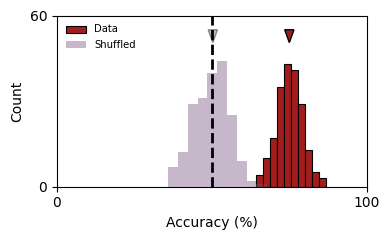

In [16]:
plot_xlim = [0,100]
plot_ylim = [0,60]
plot_trans = 1
plot_edgecolor = [0,0,0]
figure_size = np.array((4,2.5)) * 1
plot_edgewidth = figure_size[0]*.2
fig_lw = figure_size[0]*.5
save_fig = 0

plt.figure(figsize=figure_size)

plt.hist(acc_coh_bt, color=color_ob_n, linewidth=plot_edgewidth, ec=plot_edgecolor, alpha=plot_trans, label='Data')
plt.hist(acc_coh_shuff_bt, color=color_mpfc_n, alpha=plot_trans-.6, label='Shuffled')

plt.axvline(chance_level, lw=fig_lw, color='k', ls='--')

plt.arrow(np.nanmedian(acc_coh_bt), 55, 0, -.0001, head_length=4.5, head_width=3, ec=plot_edgecolor, color=color_ob_n)
plt.arrow(np.nanmedian(acc_coh_shuff_bt), 55, 0, -.0001, head_length=4.5, head_width=3, ec=None, color=color_mpfc_n, alpha=plot_trans-.6)

plt.xlim(plot_xlim)
plt.xticks(plot_xlim)
plt.xlabel('Accuracy (%)')

plt.ylim(plot_ylim)
plt.yticks(plot_ylim)
plt.ylabel('Count')

plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper left', fontsize=figure_size[0]*1.8)

print(f"BT Accuracy  ->  Data    : {np.nanmedian(acc_coh_bt)} -+ {np.nanstd(acc_coh_bt)}")
print(f"BT Accuracy  ->  Shuffled: {np.nanmedian(acc_coh_shuff_bt)} -+ {np.nanstd(acc_coh_shuff_bt)}")
print(f"BT Permutation p-val: {comp_permute_p(acc_coh_bt, acc_coh_shuff_bt)}")
print(f"BT d-prime: {compute_dprime(acc_coh_bt, acc_coh_shuff_bt)}")

if save_fig: plt.savefig(f'{FigDir}coh_acc_bt.svg')

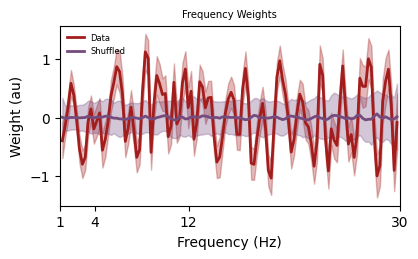

In [6]:
smooth_win = 0
plot_xlim = [min(freqs), max(freqs)]
plot_xticks = [1,4,12,30]
plot_ylim = [-.2,.8]
figure_size = np.array((4,2.5)) * 1
save_fig = 0

m_plot([freqwt_coh_bt, freqwt_coh_shuff_bt], [color_ob,color_mpfc]
       , error_method='std', smooth_win=smooth_win
       , labels=['Data','Shuffled'], plot_title=f'Frequency Weights'
       , XAxisTicks=freqs, figure_size=figure_size)

plt.xlabel('Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.ylabel('Weight (au)')
# plt.ylim(plot_ylim)
# plt.yticks([plot_ylim[0], base_level, plot_ylim[1]])

clear_output()
if save_fig: plt.savefig(f'{FigDir}coherence.svg')

In [7]:
freqwt_coh_bt_delta = abs(freqwt_coh_bt[:,idx_band_delta].mean(axis=1))
freqwt_coh_bt_theta = abs(freqwt_coh_bt[:,idx_band_theta].mean(axis=1))
freqwt_coh_bt_beta  = abs(freqwt_coh_bt[:,idx_band_beta].mean(axis=1))
ave_fw = np.concatenate((freqwt_coh_bt_delta, freqwt_coh_bt_theta,freqwt_coh_bt_beta)).reshape(3,-1).T

freqwt_coh_shuff_bt_delta = abs(freqwt_coh_shuff_bt[:,idx_band_delta].mean(axis=1))
freqwt_coh_shuff_bt_theta = abs(freqwt_coh_shuff_bt[:,idx_band_theta].mean(axis=1))
freqwt_coh_shuff_bt_beta  = abs(freqwt_coh_shuff_bt[:,idx_band_beta].mean(axis=1))
ave_fw_shuff = np.concatenate((freqwt_coh_shuff_bt_delta, freqwt_coh_shuff_bt_theta,freqwt_coh_shuff_bt_beta)).reshape(3,-1).T


Delta -> Data    : 0.12894614071485555 -+ 0.040022257953861474
Delta -> Shuffled: 0.03670913957907322 -+ 0.03017681787980367
Delta -> p-value: 1.999960000799984e-05 | d-prime: 2.602399245571828
----------
Theta -> Data    : 0.18611600695104813 -+ 0.02547709535841664
Theta -> Shuffled: 0.023987179596645713 -+ 0.018585760616308553
Theta -> p-value: 1.999960000799984e-05 | d-prime: 7.270596317057148
----------
Beta -> Data    : 0.010102257918882876 -+ 0.007496903397166095
Beta -> Shuffled: 0.013639248514859884 -+ 0.010559062751426119
Beta -> p-value: 0.0001399972000559989 | d-prime: -0.3862653766397891
----------


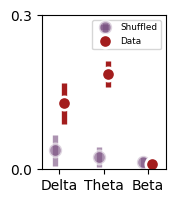

In [13]:
plot_xticks = ['Delta', 'Theta', 'Beta']
plot_trans = 1
plot_xlim = [-.4,2.4]
plot_ylim = [0,.3]
figure_size = np.array((.8,1)) * 2
plot_bar_thickness = .5 # figure_size[0]*.06
plot_err_lw = figure_size[0]*2.4
plot_err_ms = figure_size[0]*12
plot_edge_lw = figure_size[0]*1.2
plot_edge_markerw = figure_size[0]*1.2
save_fig = 0

plt.figure(figsize=figure_size)

plt.errorbar(np.arange(ave_fw_shuff.shape[1]) -.1, np.nanmean(ave_fw_shuff,axis=0), xerr=0, yerr=np.nanstd(ave_fw_shuff,axis=0)
             , fmt='.', markersize=plot_err_ms, markeredgecolor=[1,1,1], markeredgewidth=plot_edge_markerw
             , elinewidth=plot_err_lw, color=color_mpfc_n, alpha=plot_trans-.4, label='Shuffled')

plt.errorbar(np.arange(ave_fw.shape[1]) +.1, np.nanmean(ave_fw,axis=0), xerr=0, yerr=np.nanstd(ave_fw,axis=0)
             , fmt='.', markersize=plot_err_ms, markeredgecolor=[1,1,1], markeredgewidth=plot_edge_markerw
             , elinewidth=plot_err_lw, color=color_ob_n, alpha=plot_trans, label='Data')

plt.xlim(plot_xlim)
plt.xticks(np.arange(ave_fw.shape[1]), plot_xticks)
plt.ylim(plot_ylim)
plt.yticks(plot_ylim)

plt.legend(['Shuffled', 'Data'], frameon=True, ncol=1, fontsize=figure_size[0]*4)

if 1: 
    for iBand,band in enumerate(plot_xticks):
        print(f'{band} -> Data    : {np.nanmean(ave_fw[:,iBand])} -+ {np.nanstd(ave_fw[:,iBand])}')
        print(f'{band} -> Shuffled: {np.nanmean(ave_fw_shuff[:,iBand])} -+ {np.nanstd(ave_fw_shuff[:,iBand])}')
        print(f'{band} -> p-value: {comp_permute_p(ave_fw[:,iBand], ave_fw_shuff[:,iBand])} | d-prime: {compute_dprime(ave_fw[:,iBand], ave_fw_shuff[:,iBand])}')
        print(f'----------')

if save_fig: plt.savefig(f'{FigDir}coherence_ml_freqwt.svg')